# Attention maps for CLS and Register Tokens 

The following function was used to compute the CLS Tokens and Register Tokens using Dinov2 model (with and without registers) and save the images as png files. The input of the function can be modified based on the type of attention map you are trying to extract. Please note that in order to run the following function you must download the pretrained DINO models (with and without registers). Link to the pretrained models: https://github.com/facebookresearch/dinov2?tab=readme-ov-file

In [24]:
def save_attention_map(folder, file, content):
    fname = os.path.join(folder, file)
    plt.imsave(fname=fname, arr=content, format='png')
    print(f"{fname} saved.") 

In [31]:
import os
import sys
import argparse
import cv2
import random
import colorsys
import requests
from io import BytesIO

import skimage.io
from skimage.measure import find_contours
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
import torch
import torch.nn as nn
import torchvision
from torchvision import transforms as pth_transforms
import numpy as np
from PIL import Image
from dinov2.models.vision_transformer import vit_small, vit_large


def create_attention_maps(pth, regs, token):
    image_size = (952, 952)
    output_dir = '.'
    patch_size = 14

    device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
    
    img = Image.open(input_file)
    img = img.convert('RGB')
    transform = pth_transforms.Compose([
        pth_transforms.Resize(image_size),
        pth_transforms.ToTensor(),
        pth_transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
    ])
    img = transform(img)
    print(img.shape)

    # make the image divisible by the patch size
    w, h = img.shape[1] - img.shape[1] % patch_size, img.shape[2] - img.shape[2] % patch_size
    img = img[:, :w, :h].unsqueeze(0)

    w_featmap = img.shape[-2] // patch_size
    h_featmap = img.shape[-1] // patch_size

    print(img.shape)
    
    if regs:
        model = vit_large(
                patch_size=14,
                img_size=526,
                num_register_tokens=4, 
                init_values=1.0,
                #ffn_layer="mlp",
                block_chunks=0)
    else:
        model = vit_large(
                patch_size=14,
                img_size=526,
                init_values=1.0,
                #ffn_layer="mlp",
                block_chunks=0)
    
    cwd = os.getcwd()
    pretrained_model= os.path.join(cwd, pth)

    model.load_state_dict(torch.load(pretrained_model))
    for p in model.parameters():
        p.requires_grad = False
        
    model.to(device).eval()

    attentions = model.get_last_self_attention(img.to(device))
    
    print(attentions.shape)
    
    nh = attentions.shape[1] # number of head

    # we keep only the output patch attention
    # for every patch
    sum_attention = np.zeros((952, 952))
    mean_attention = np.zeros((952, 952))

    
    # Registers - save all 4 and aggregated version 
    if token == 'REG':
        
        # for each register token we save the average of the attention heads 
        for i in range(1,5):
            
            register = attentions[0, :, i, 5:].reshape(nh, -1)
            register = register.reshape(nh, w_featmap, h_featmap)
            register = nn.functional.interpolate(register.unsqueeze(0), scale_factor=patch_size, mode="nearest")[0].cpu().numpy()
            
            # each regoster has 16 attention heads. we save the sum and the average of all 16 attention heads to create 1 image
            avg_reg = register.mean(axis=0)
            sum_reg = register.sum(axis=0)
             
            save_attention_map(output_dir,  "avg_reg_-" + str(i) + ".png", avg_reg)  
            save_attention_map(output_dir,  "sum_reg_" + str(i) + ".png", sum_reg)  
            
            mean_attention += avg_reg / 4
            sum_attention += sum_reg

        save_attention_map(output_dir,  "AVG_REG.png", mean_attention)  
        save_attention_map(output_dir,  "SUM_REG.png", sum_attention) 
    
    
    # CLS - save attention heads and aggregated data 
    elif token == 'CLS':
        
        if regs:
            attentions = attentions[0, :, 0, 5:].reshape(nh, -1)
        else:
            attentions = attentions[0, :, 0, 1:].reshape(nh, -1)
            
        attentions = attentions.reshape(nh, w_featmap, h_featmap)
        attentions = nn.functional.interpolate(attentions.unsqueeze(0), scale_factor=patch_size, mode="nearest")[0].cpu().numpy()

        # save attentions heatmaps
        os.makedirs(output_dir, exist_ok=True)

        # save each attention head heatmap as png 
        for j in range(nh):
            save_attention_map(output_dir,  "CLS_h" + str(j) + ".png", attentions[j])  

        average_attention = attentions.mean(axis=0)
        sum_attention = attentions.sum(axis=0)
        max_attention = attentions.max(axis=0)
        
        save_attention_map(output_dir,  "CLS_AVG.png", average_attention)  
        save_attention_map(output_dir,  "CLS_SUM.png", sum_attention)  
        save_attention_map(output_dir,  "CLS_Max.png", max_attention)  



In [32]:
pth_regs= "dinov2_vitl14_reg4_pretrain.pth"
pth_no_regs= "dinov2_vitl14_pretrain.pth"
dino_1= "dinov2_vitl14_pretrain.pth"
input_file=  os.path.join(cwd, "dog.jpg")

create_attention_maps(dino_1, regs=False, token="CLS")

# create_attention_maps(pth_regs, regs=True, token="CLS")

torch.Size([3, 952, 952])
torch.Size([1, 3, 952, 952])
torch.Size([1, 16, 4625, 4625])
.\CLS_h0.png saved.
.\CLS_h1.png saved.
.\CLS_h2.png saved.
.\CLS_h3.png saved.
.\CLS_h4.png saved.
.\CLS_h5.png saved.
.\CLS_h6.png saved.
.\CLS_h7.png saved.
.\CLS_h8.png saved.
.\CLS_h9.png saved.
.\CLS_h10.png saved.
.\CLS_h11.png saved.
.\CLS_h12.png saved.
.\CLS_h13.png saved.
.\CLS_h14.png saved.
.\CLS_h15.png saved.
.\CLS_Max.png saved.


# Attention Map Example of Register 1 on Dog Image 

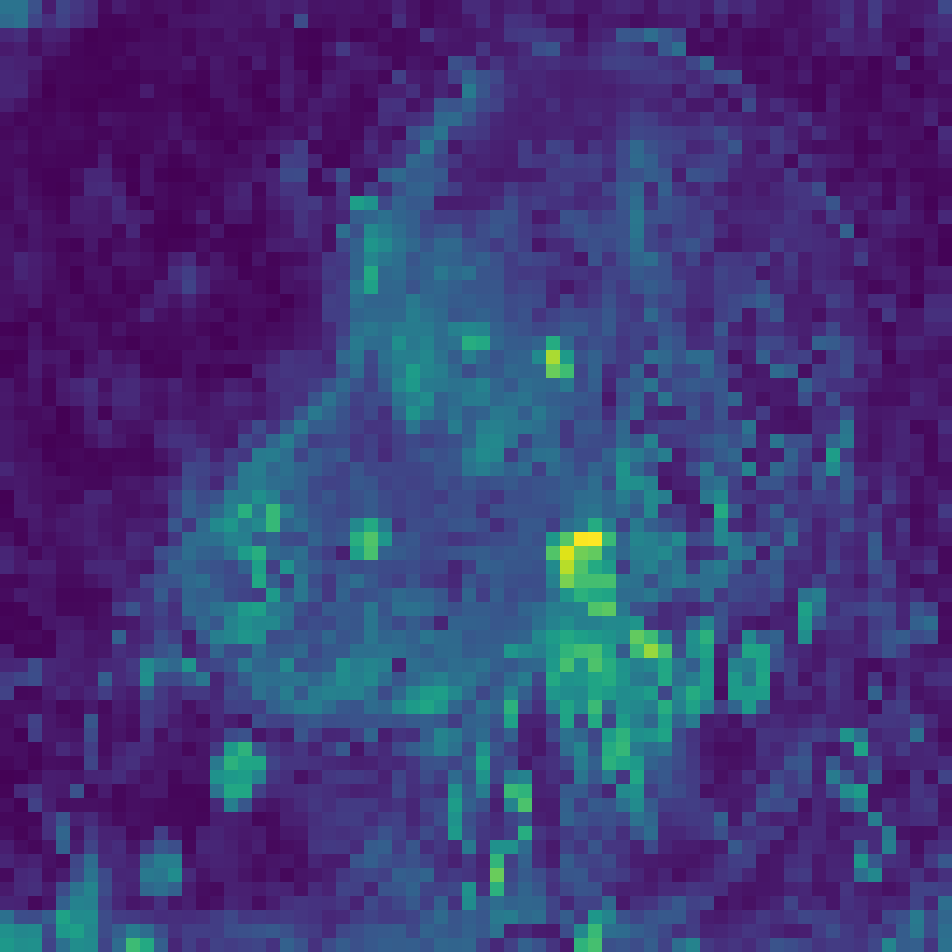

In [35]:
from IPython.display import Image, display
display(Image(filename='Dog_maps/reg-1.png'))